In [3]:
# Import the libraries
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np

# Demonstrator 1 - Diffusive and dispersive properties of the advection schemes

## Aim of Tutorial

The aim of this tutorial is to give the readers an opportunity to run the salt block simulation using the different advection schemes. Here we choose to use the transport of a block of salt to demonstrate how the diffusive and dispersive properties of the advection scheme impact the outcome of a simulation.

To run this demonstrator you must have followed Tutorial 1 beforehand.

## Dispersive scheme 

### Running the simulation

An example of a dispersive scheme in NEMO 5.0 is the CENtred advection scheme (CEN).
To run a CEN2 simulation, we need to change ```ln_traadv_cen``` from ```.false.``` to ```.true.``` and ```nn_cen_h``` and ```nn_cen_v``` from ```4``` to ```2``` in the namelist.

__To make the recquired changes you can either modify the files yourself by following the instructions starting 2 cells below or you can execute the cell below__

In [92]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00

cd /"$DIR"

#We have to remove any file with the same name before running the simulation out of precaution
rm CANAL_saltblock_cen2_all_grid.nc

chmod -R a+x /"$DIR"/demo1_cfg/

bash /"$DIR"/demo1_cfg/saltblock_cfg.sh "$DIR"
bash /"$DIR"/demo1_cfg/cen2_cfg.sh "$DIR"
bash /"$DIR"/demo1_cfg/cen4_cfg.sh "$DIR"


rn_salszx, rn_salszy already in the file, insertion ignored.
57c57
<    cn_exp =	'CANAL_saltblock_cen4'			                  		                  	      		                  			                                                                                          	                                    		 !  experience name
---
>    cn_exp	=	'CANAL_saltblock'			                  		                  	      		                  			                                                                                          	                                    		 !  experience name
57c57
<    cn_exp =	'CANAL_saltblock_cen2'				                  		                  	      		                  			                                                                                          	                                    		 !  experience name
---
>    cn_exp	=	'CANAL_saltblock'			                  		                  	      		                  			                                                     


real	1m20.019s
user	4m8.112s
sys	0m23.582s



Everything looks good

Run CANAL_saltblock_cen2_all_grid.nc completed


In [93]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00

cd /"$DIR"

#We have to remove any file with the same name before running the simulation out of precaution
rm CANAL_saltblock_cen4_all_grid.nc

bash /"$DIR"/demo1_cfg/cen4_cfg.sh "$DIR"


57c57
<    cn_exp =	'CANAL_saltblock_cen4'					                  		                  	      		                  			                                                                                          	                                    		 !  experience name
---
>    cn_exp =	'CANAL_saltblock_cen2'				                  		                  	      		                  			                                                                                          	                                    		 !  experience name
167,168c167,168
<       nn_cen_h	=	4		!  =2/4, horizontal 2nd order CEN / 4th order CEN
<       nn_cen_v  =       4		!  =2/4, vertical   2nd order CEN / 4th order COMPACT
---
>       nn_cen_h	=	2		!  =2/4, horizontal 2nd order CEN / 4th order CEN
>       nn_cen_v  =       2		!  =2/4, vertical   2nd order CEN / 4th order COMPACT



real	1m17.933s
user	4m12.055s
sys	0m22.370s



Everything looks good

Run CANAL_saltblock_cen4_all_grid.nc completed


```
&namtra_adv    !   advection scheme for tracer                          (default: NO selection)
!-----------------------------------------------------------------------
   ln_traadv_OFF = .false. !  No tracer advection
   ln_traadv_cen = .true. !  2nd order centered scheme
      nn_cen_h   =  2            !  =2/4, horizontal 2nd order CEN / 4th order CEN
      nn_cen_v   =  2            !  =2/4, vertical   2nd order CEN / 4th order COMPACT
   ln_traadv_fct = .false. !  FCT scheme
      nn_fct_h   =  2            !  =2/4, horizontal 2nd / 4th order
      nn_fct_v   =  2            !  =2/4, vertical   2nd / COMPACT 4th order
   ln_traadv_mus = .false. !  MUSCL scheme
      ln_mus_ups = .false.       !  use upstream scheme near river mouths
   ln_traadv_ubs = .false.  !  UBS scheme
      nn_ubs_v   =  2            !  =2  , vertical 2nd order FCT / COMPACT 4th order
   ln_traadv_qck = .false. !  QUICKEST scheme
/```

Change the name of the experience ```cn_exp``` from ```CANAL_saltblock``` to ```CANAL_saltblock_cen2``` so as not to overwrite the data when running other simulations later on.

We can now run the simulation using the ./run_nemo command

### Analysis of the outcome

In [94]:
#Insert below the name of the directory in which you will run the simulations /.../EXP$$
rep = ''


cen2 = xr.open_dataset(rep+'CANAL_saltblock_cen2_all_grid.nc')
cen4 = xr.open_dataset(rep+'CANAL_saltblock_cen4_all_grid.nc')

A dispersive scheme such as CEN causes different frequency components of a wave to travel at incorrect and varying speeds, creating spurious wiggles or phase shifts. The oscillations of values of the salinity tracer you should see around the edges of the block are symptomatic of the incorrect propagation occuring in a dispersive scheme. 

A consequence of these oscillations due to discontinuous data is the Gibbs Phenomenon where high-order linear schemes attempting to resolve a sharp step will always produce an overshoot/undershoot 
near the discontinuity if they lack sufficient numerical diffusion to damp them out.

Areas where overshoot/undershoot are produced should appear in yellow.

## Diffusive scheme 

### Running the simulation

An example of a diffusive scheme in NEMO 5.0 is the Upstream Biased Scheme (UBS).
To run a UBS simulation, we need to change ```ln_traadv_ubs``` from ```.false.``` to ```.true.``` in the namelist and set ```nn_ubs_v``` to ```2```.

__To make the recquired changes you can either modify the files yourself by following the instructions starting 2 cells below or you can execute the cell below__

In [107]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00

cd /"$DIR"

#We have to remove any file with the same name before running the simulation out of precaution
rm CANAL_saltblock_ubs_all_grid.nc

chmod -R a+x /"$DIR"/demo1_cfg/


bash /"$DIR"/demo1_cfg/saltblock_cfg.sh "$DIR"
bash /"$DIR"/demo1_cfg/ubs_cfg.sh "$DIR"


rm: impossible de supprimer 'CANAL_saltblock_ubs_all_grid.nc': No such file or directory


rn_salszx, rn_salszy already in the file, insertion ignored.
57c57
<    cn_exp =	'CANAL_saltblock_cen4'					                  		                  	      		                  			                                                                                          	                                    		 !  experience name
---
>    cn_exp	=	'CANAL_saltblock'					                  		                  	      		                  			                                                                                          	                                    		 !  experience name
57c57
<    cn_exp =  'CANAL_saltblock_ubs'      					                  		                  	      		                  			                                                                                          	                                    		 !  experience name
---
>    cn_exp	=	'CANAL_saltblock'					                  		                  	      		                  			                                        


real	1m23.028s
user	4m17.047s
sys	0m24.497s



Everything looks good

Run CANAL_saltblock_ubs_all_grid.nc completed


```
&namtra_adv    !   advection scheme for tracer                          (default: NO selection)
!-----------------------------------------------------------------------
   ln_traadv_OFF = .false. !  No tracer advection
   ln_traadv_cen = .false. !  2nd order centered scheme
      nn_cen_h   =  2            !  =2/4, horizontal 2nd order CEN / 4th order CEN
      nn_cen_v   =  2            !  =2/4, vertical   2nd order CEN / 4th order COMPACT
   ln_traadv_fct = .false. !  FCT scheme
      nn_fct_h   =  2            !  =2/4, horizontal 2nd / 4th order
      nn_fct_v   =  2            !  =2/4, vertical   2nd / COMPACT 4th order
   ln_traadv_mus = .false. !  MUSCL scheme
      ln_mus_ups = .false.       !  use upstream scheme near river mouths
   ln_traadv_ubs = .true.  !  UBS scheme
      nn_ubs_v   =  2            !  =2  , vertical 2nd order FCT / COMPACT 4th order
   ln_traadv_qck = .false. !  QUICKEST scheme
/```

Change the name of the experience ```cn_exp``` from ```CANAL_saltblock``` to ```CANAL_saltblock_ubs``` so as not to overwrite the data when running other simulations later on.

We can now run the simulation using the ./run_nemo command

### Analysis of the outcome

In [108]:
#Open the simulation using the xr library

ubs = xr.open_dataset(rep+'CANAL_saltblock_ubs_all_grid.nc')

UBS is a diffusive scheme, it acts like artificial viscosity,  it should cause peaks to flatten and sharp edges to blur. 

The UBS scheme is not positive either, meaning that false extrema (highlighted in yellow above) are permitted, but the amplitude of such are significantly reduced compared to CEN2 as shown below.

The UBS scheme is not positive either, meaning that false extrema (highlighted in yellow above) are permitted, but the amplitude of such are significantly reduced compared to CEN2 as shown below.

## Corrected scheme 

### Running the simulation

An example of a corrected scheme in NEMO 5.0 is the Flux Corrected Transport scheme (FCT).
To run a FCT simulation, we need to change ```ln_traadv_fct``` from ```.false.``` to ```.true.``` and the ```nn_fct_h``` and ```nn_fct_v``` from ```4``` to ```2``` in the namelist.

__To make the recquired changes you can either modify the files yourself by following the instructions starting 2 cells below or you can execute the cell below__

In [112]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00

cd /"$DIR"

#We have to remove any file with the same name before running the simulation out of precaution
rm CANAL_saltblock_fct2_all_grid.nc

chmod -R a+x /"$DIR"/demo1_cfg/


bash /"$DIR"/demo1_cfg/saltblock_cfg.sh "$DIR"
bash /"$DIR"/demo1_cfg/fct2_cfg.sh "$DIR"

rm: impossible de supprimer 'CANAL_saltblock_fct2_all_grid.nc': No such file or directory


rn_salszx, rn_salszy already in the file, insertion ignored.
57c57
<    cn_exp =  'CANAL_saltblock_ubs'      					                  		                  	      		                  			                                                                                          	                                    		 !  experience name
---
>    cn_exp	=	'CANAL_saltblock'      					                  		                  	      		                  			                                                                                          	                                    		 !  experience name
57c57
<    cn_exp =  'CANAL_saltblock_fct2'            					                  		                  	      		                  			                                                                                          	                                    		 !  experience name
---
>    cn_exp	=	'CANAL_saltblock'      					                  		                  	      		                  			               


real	1m35.956s
user	4m22.967s
sys	0m29.479s



Everything looks good

Run CANAL_saltblock_fct2_all_grid.nc completed


In [113]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00

cd /"$DIR"

#We have to remove any file with the same name before running the simulation out of precaution
rm CANAL_saltblock_fct4_all_grid.nc

bash /"$DIR"/demo1_cfg/fct4_cfg.sh "$DIR"

rm: impossible de supprimer 'CANAL_saltblock_fct4_all_grid.nc': No such file or directory


57c57
<    cn_exp =  'CANAL_saltblock_fct4'                  					                  		                  	      		                  			                                                                                          	                                    		 !  experience name
---
>    cn_exp =  'CANAL_saltblock_fct2'            					                  		                  	      		                  			                                                                                          	                                    		 !  experience name
170,171c170,171
<       nn_fct_h  =       4               !  =2/4, horizontal 2nd / 4th order
<       nn_fct_v  =       4               !  =2/4, vertical   2nd / COMPACT 4th order
---
>       nn_fct_h  =       2               !  =2/4, horizontal 2nd / 4th order
>       nn_fct_v  =       2               !  =2/4, vertical   2nd / COMPACT 4th order



real	1m28.087s
user	4m23.677s
sys	0m26.724s



Everything looks good

Run CANAL_saltblock_fct2_all_grid.nc completed


```
&namtra_adv    !   advection scheme for tracer                          (default: NO selection)
!-----------------------------------------------------------------------
   ln_traadv_OFF = .false. !  No tracer advection
   ln_traadv_cen = .false. !  2nd order centered scheme
      nn_cen_h   =  2            !  =2/4, horizontal 2nd order CEN / 4th order CEN
      nn_cen_v   =  2            !  =2/4, vertical   2nd order CEN / 4th order COMPACT
   ln_traadv_fct = .true. !  FCT scheme
      nn_fct_h   =  2            !  =2/4, horizontal 2nd / 4th order
      nn_fct_v   =  2            !  =2/4, vertical   2nd / COMPACT 4th order
   ln_traadv_mus = .false. !  MUSCL scheme
      ln_mus_ups = .false.       !  use upstream scheme near river mouths
   ln_traadv_ubs = .false.  !  UBS scheme
      nn_ubs_v   =  2            !  =2  , vertical 2nd order FCT / COMPACT 4th order
   ln_traadv_qck = .false. !  QUICKEST scheme
/```

Change the name of the experience ```cn_exp``` from ```CANAL_saltblock``` to ```CANAL_saltblock_fct2``` so as not to overwrite the data when running other simulations later on.

We can now run the simulation using the ./run_nemo command

### Analysis of the outcome

FCT2 is also a scheme where a dispersive scheme is combined with a diffusive scheme.

In [246]:
fct2 = xr.open_dataset(rep+'CANAL_saltblock_fct2_all_grid.nc')
fct4 = xr.open_dataset(rep+'CANAL_saltblock_fct4_all_grid.nc')

The diffusive scheme is activated when a local extremum is produced and it is used to corrects the side lobe. That is why we should not see values over the maximum initial value of salinity or values under the mininum initial value of salinity.

## Comparative plots

In [387]:
block_0 = xr.open_dataset(rep+'CANAL_saltblock_traadvOFF_all_grid.nc', decode_times=False)
block_0 =block_0.soce.isel(y_grid_T = 50, time_counter=0, deptht=0)

v= 0.5
dx = 10000
ref = []

for t in range (80):
    ref.append(np.roll(block_0, shift=v*86400*(t+1)/dx))
    
print(ref[0].shape)

(87,)


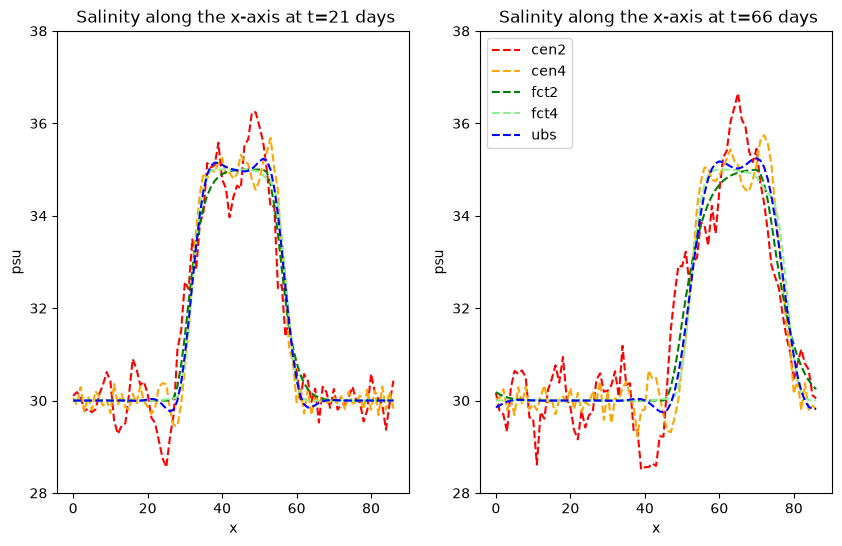

In [389]:
fig, ax = plt.subplots(1, 2, figsize=(10,6))

#ax[0].plot(np.arange(len(ref[0])), ref[20], color ='black', label ='reference')
ax[0].plot(np.arange(cen2['soce'].shape[3]), cen2['soce'].isel(time_counter=20, y_grid_T=50, deptht=0), '--', color ='red', label = 'cen2')
ax[0].plot(np.arange(cen4['soce'].shape[3]), cen4['soce'].isel(time_counter=20, y_grid_T=50, deptht=0), '--', color ='orange', label ='cen4')
ax[0].plot(np.arange(fct2['soce'].shape[3]), fct2['soce'].isel(time_counter=20, y_grid_T=50, deptht=0), '--', color ='green', label = 'fct2')
ax[0].plot(np.arange(fct4['soce'].shape[3]), fct4['soce'].isel(time_counter=20, y_grid_T=50, deptht=0), '--', color ='lightgreen', label = 'fct4')
ax[0].plot(np.arange(ubs['soce'].shape[3]), ubs['soce'].isel(time_counter=20, y_grid_T=50, deptht=0), '--', color ='blue', label ='ubs')
ax[0].set_xlabel('x')
ax[0].set_ylabel('psu')
ax[0].set_ylim(28,38)
ax[0].set_title(f' Salinity along the x-axis at t=21 days')

#ax[1].plot(np.arange(len(ref[0])), ref[65], color ='black', label ='reference')
ax[1].plot(np.arange(cen2['soce'].shape[3]), cen2['soce'].isel(time_counter=65, y_grid_T=50, deptht=0), '--', color ='red', label = 'cen2')
ax[1].plot(np.arange(cen4['soce'].shape[3]), cen4['soce'].isel(time_counter=65, y_grid_T=50, deptht=0), '--', color ='orange', label ='cen4')
ax[1].plot(np.arange(fct2['soce'].shape[3]), fct2['soce'].isel(time_counter=65, y_grid_T=50, deptht=0), '--', color ='green', label = 'fct2')
ax[1].plot(np.arange(fct4['soce'].shape[3]), fct4['soce'].isel(time_counter=65, y_grid_T=50, deptht=0), '--', color ='lightgreen', label = 'fct4')
ax[1].plot(np.arange(ubs['soce'].shape[3]), ubs['soce'].isel(time_counter=65, y_grid_T=50, deptht=0), '--', color ='blue', label = 'ubs')
ax[1].set_xlabel('x')
ax[1].set_ylabel('psu')
ax[1].set_ylim(28,38)
ax[1].set_title(f' Salinity along the x-axis at t=66 days')

plt.legend()

In [392]:
block_0 = xr.open_dataset(rep+'CANAL_saltblock_traadvOFF_all_grid.nc').sssgrad.isel(y_grid_T = 50, time_counter = 0)

ref_grad = []

for t in range (80):
    ref_grad.append(np.roll(block_0, shift=v*86400*(t+0.5)/dx)) 
    """ce 0.5 me pose probleme, cela veut dire que soit la sortie 
        est prise en milieu de journee pas en fin de journee comme on avait convenu
        normalement ce n'est pas la moyenne de la journee c'est sur car j'ai bien verifie 
        dans def_field qu'on etait en operation=instant"""
print(ref[0].shape)

(87,)


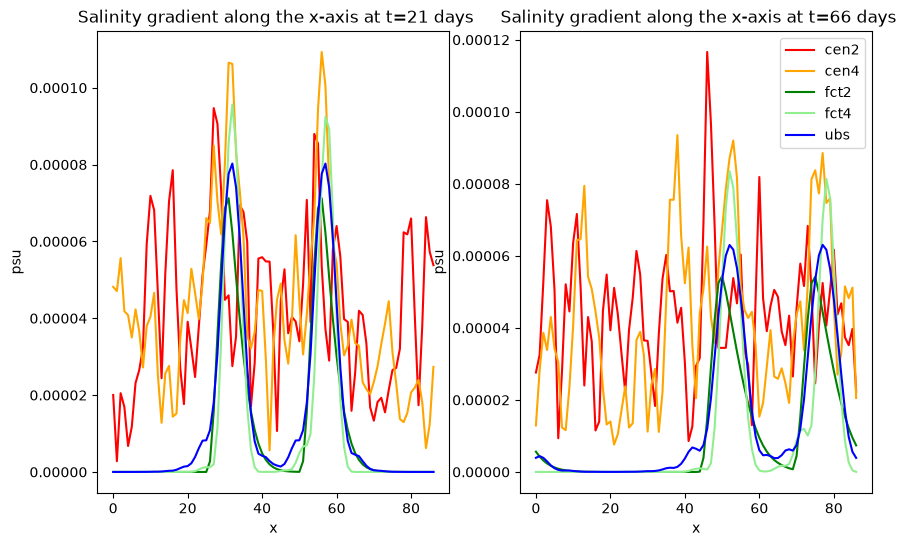

In [393]:
fig, ax = plt.subplots(1, 2, figsize=(10,6))

#ax[0].plot(np.arange(len(ref_grad[0])), ref_grad[20], color ='black', label ='reference')
ax[0].plot(np.arange(cen2['sssgrad'].shape[2]), cen2['sssgrad'].isel(time_counter=20, y_grid_T=50), color ='red', label = 'cen2')
ax[0].plot(np.arange(cen4['sssgrad'].shape[2]), cen4['sssgrad'].isel(time_counter=20, y_grid_T=50), color ='orange', label ='cen4')
ax[0].plot(np.arange(fct2['sssgrad'].shape[2]), fct2['sssgrad'].isel(time_counter=20, y_grid_T=50), color ='green', label = 'fct2')
ax[0].plot(np.arange(fct4['sssgrad'].shape[2]), fct4['sssgrad'].isel(time_counter=20, y_grid_T=50), color ='lightgreen', label = 'fct4')
ax[0].plot(np.arange(ubs['sssgrad'].shape[2]), ubs['sssgrad'].isel(time_counter=20, y_grid_T=50), color ='blue', label ='ubs')
ax[0].set_xlabel('x')
ax[0].set_ylabel('psu')
ax[0].set_title(f' Salinity gradient along the x-axis at t=21 days')

#ax[1].plot(np.arange(len(ref_grad[0])), ref_grad[20], color ='black', label ='reference')
ax[1].plot(np.arange(cen2['sssgrad'].shape[2]), cen2['sssgrad'].isel(time_counter=65, y_grid_T=50), color ='red', label = 'cen2')
ax[1].plot(np.arange(cen4['sssgrad'].shape[2]), cen4['sssgrad'].isel(time_counter=65, y_grid_T=50), color ='orange', label ='cen4')
ax[1].plot(np.arange(fct2['sssgrad'].shape[2]), fct2['sssgrad'].isel(time_counter=65, y_grid_T=50), color ='green', label = 'fct2')
ax[1].plot(np.arange(fct4['sssgrad'].shape[2]), fct4['sssgrad'].isel(time_counter=65, y_grid_T=50), color ='lightgreen', label = 'fct4')
ax[1].plot(np.arange(ubs['sssgrad'].shape[2]), ubs['sssgrad'].isel(time_counter=65, y_grid_T=50), color ='blue', label = 'ubs')
ax[1].set_xlabel('x')
ax[1].set_ylabel('psu')
ax[1].set_title(f' Salinity gradient along the x-axis at t=66 days')

plt.legend()

To better visualize the oscillations of the CEN2 signal let us trace the salinity of one fixed point in space through time.You should see oscillations near discontinuities. These represent the different frequency components of the square wave traveling at incorrect and varying speeds

For the UBS graph, the artefacts of the dispersive component are the oscillations near the sharp edges, the drops below 30 and the values over 35. The artecfacts of the diffusive components are the peaks and sharp edges being smoothed out. As the effect of the dispersive component counters the effect of the diffusive component (the oscillations produced by the the dispersive component are smoothed out by the diffusive component), it is quite difficult to make a diagnosis out of the figure other than the overshoot/undershoot.

Similarly to the UBS scheme, a "dampening", a flattening of the sharp peaks of the FCT2 square wave should be seen. As the side lobes are automatically fully corrected as soon as they appear they cannot spread oscillations.

We do not see the periodic peaks that represent the front and the back of the square because the CEN2 scheme distorted the shape of the square. 

The amplitude of high magnitude gradients for UBS and FCT2 should decay (dampening effect) compared to the CEN2 graph.

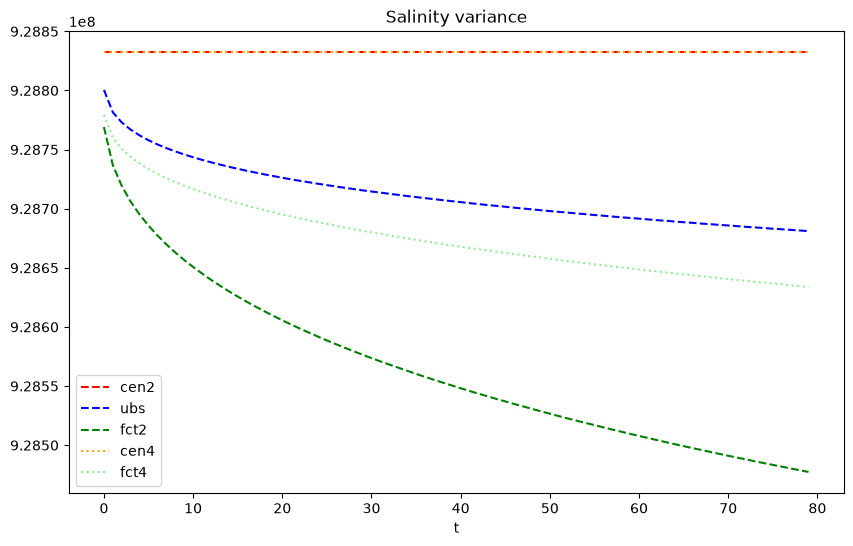

In [120]:
fig_salt2c, axes_salt2c = plt.subplots(1, 1, figsize=(10, 6))

s2c = cen2['salt2c'].mean(dim=('x_grid_T', 'y_grid_T'))
dep = np.arange(s2c.shape[0])
axes_salt2c.plot(dep,  s2c, '--', color = 'red', label = 'cen2')

s2c = ubs['salt2c'].mean(dim=('x_grid_T', 'y_grid_T'))
dep = np.arange(s2c.shape[0])
axes_salt2c.plot(dep,  s2c, '--', color = 'blue', label = 'ubs')

s2c = fct2['salt2c'].mean(dim=('x_grid_T', 'y_grid_T'))
dep = np.arange(s2c.shape[0])
axes_salt2c.plot(dep,  s2c, '--', color = 'green', label = 'fct2')

s2c = cen4['salt2c'].mean(dim=('x_grid_T', 'y_grid_T'))
dep = np.arange(s2c.shape[0])
axes_salt2c.plot(dep,  s2c, ':', color = 'orange', label = 'cen4')

s2c = fct4['salt2c'].mean(dim=('x_grid_T', 'y_grid_T'))
dep = np.arange(s2c.shape[0])
axes_salt2c.plot(dep,  s2c, ':', color = 'lightgreen', label = 'fct4')


axes_salt2c.set_title("Salinity variance")
axes_salt2c.set_xlabel('t')

axes_salt2c.legend()

An advantage of the dispersive scheme is that the tracer variance is conserved through time.

Contrary to dispersive schemes, diffusive schemes are non-positive, the tracer variance should systematically decrease (dissipation). As the front of the square is very abrupt ir encourages the formation of side-lobes. The FCT2 first order dispersive scheme is largely sollicitated to correct the side lobes created, the scheme falls to first order in this specific example, which is why it sits so far below the UBS graph. For similar reasons FCT4 falls to 3rd order.

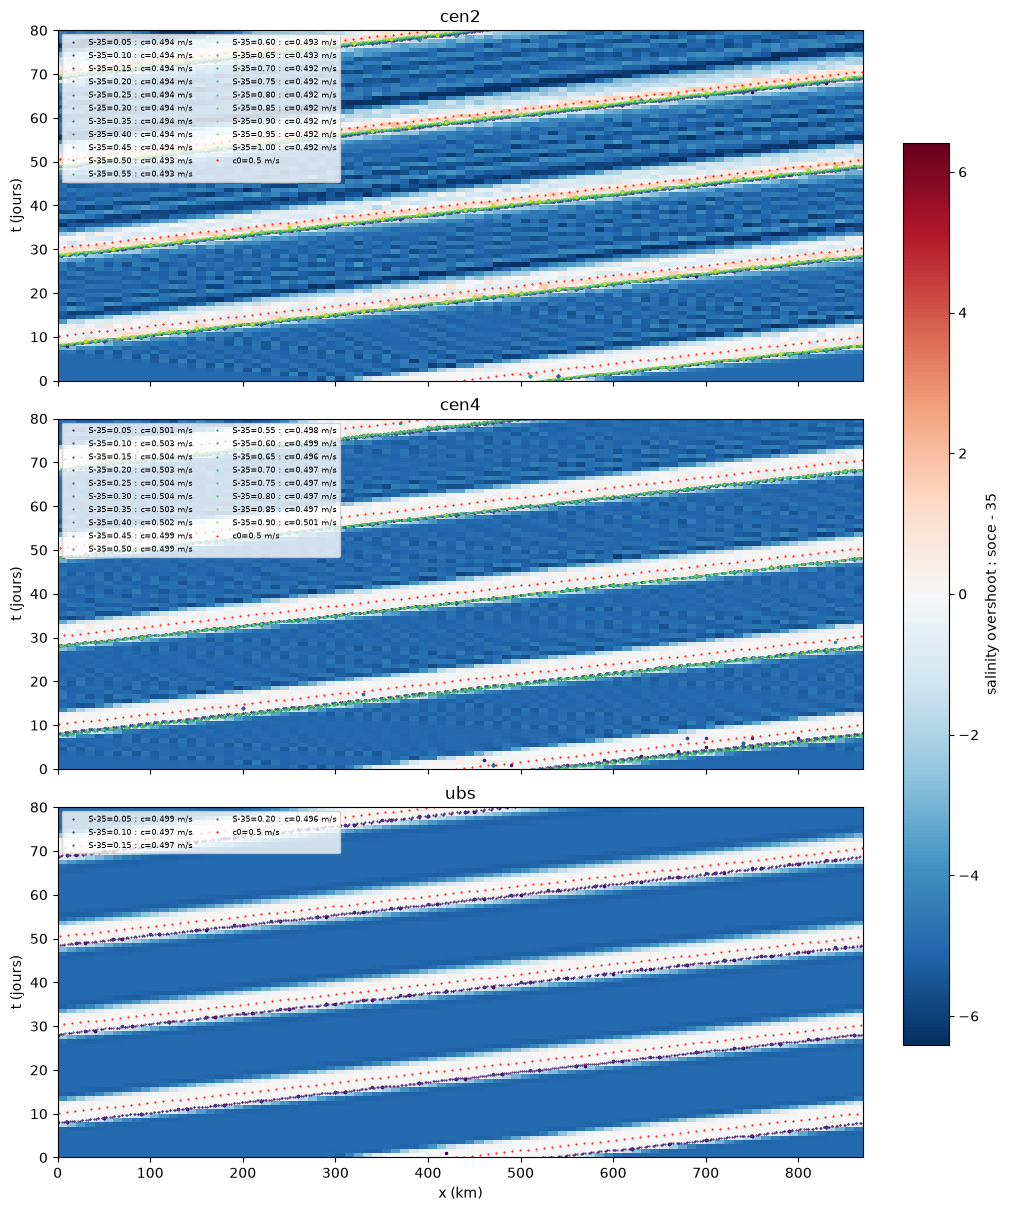

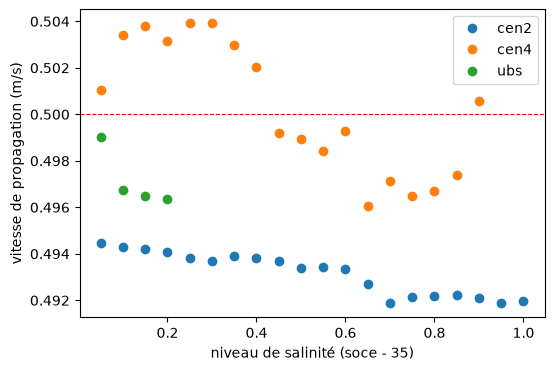

In [447]:
dx, dt, c0 = 10000., 24*3600., 0.5
x0, nt = 43, 80
levels = [0.05*k for k in range(1, 21)]
colors = plt.cm.viridis(np.linspace(0, 0.9, len(levels)))

schemes = {'cen2': cen2, 'cen4': cen4, 'ubs': ubs}
fields = {n: ds['soce'].isel(y_grid_T=50, deptht=0, time_counter=slice(0, nt)).values - 35
          for n, ds in schemes.items()}
nx = next(iter(fields.values())).shape[1]
L = nx*dx/1e3                                  # longueur du domaine (km)
t = np.arange(nt)*dt

w_back, w_front = 30, 10                       # fenêtre (mailles) ; w_back + w_front + 1 < nx
j = np.arange(-w_back, w_front + 1)

vmax = np.nanpercentile(np.abs(np.concatenate([f.ravel() for f in fields.values()])), 99.5)

def track_level(f, level):
    """Position DÉPLIÉE (m) de la maille la plus avancée où f >= level, dans une fenêtre mobile."""
    pos = np.full(f.shape[0], np.nan)
    for i in range(f.shape[0]):
        m = x0 + int(round(c0*t[i]/dx)) + j    # indices dépliés (non repliés)
        ok = np.where(f[i, m % nx] >= level)[0]
        if ok.size:
            pos[i] = m[ok.max()]*dx
    return pos

def fit_speed(t, x, tmin=0., tmax=None):
    m = np.isfinite(x) & (t >= tmin) & (t <= (tmax if tmax is not None else t.max()))
    if m.sum() < 3:
        return np.nan, np.nan, None
    p = np.polyfit(t[m], x[m], 1)
    return p[0], p[1], m

fig, axes = plt.subplots(len(fields), 1, figsize=(10, 12),
                         sharex=True, sharey=True, constrained_layout=True)
speeds = {}
tt = np.linspace(0, nt*dt, 400)

for ax, (name, f) in zip(axes, fields.items()):
    im = ax.imshow(f, origin='lower', aspect='auto', cmap='RdBu_r',
                   vmin=-vmax, vmax=vmax, interpolation='nearest',
                   extent=[0, L, 0, nt*dt/86400])
    speeds[name] = []
    for lev, col in zip(levels, colors):
        xf = track_level(f, lev)               # dépliée
        c, b, m = fit_speed(t, xf)             # régression sur tous les points valides
        speeds[name].append(c)
        if m is None:
            continue
        # affichage : on replie seulement ici
        ax.plot((xf[m]/1e3) % L, t[m]/86400, '.', ms=3, color=col)
        ax.plot((((b + c*tt)/1e3) % L), tt/86400, '.', ms=1, color=col,
                label=f'S-35={lev:.2f} : c={c:.3f} m/s')
    ax.plot(((x0*dx + c0*tt)/1e3) % L, tt/86400, 'r.', ms=1, label=f'c0={c0} m/s')
    ax.set_title(name); ax.set_ylabel('t (jours)')
    ax.set_xlim(0, L); ax.set_ylim(0, nt*dt/86400)
    ax.legend(fontsize=6, loc='upper left', ncol=2)

axes[-1].set_xlabel('x (km)')
fig.colorbar(im, ax=axes, label='salinity overshoot : soce - 35', shrink=0.8)

fig, ax = plt.subplots(figsize=(6, 4))
for name, c in speeds.items():
    ax.plot(levels, c, 'o', label=name)
ax.axhline(c0, color='r', ls='--', lw=0.8)
ax.set_xlabel('niveau de salinité (soce - 35)')
ax.set_ylabel('vitesse de propagation (m/s)')
ax.legend(); plt.show()

/var/folders/rt/k5yxzgzd793fcl03j9vc4cnm0000gs/T/ipykernel_89167/1774839174.py:11: RuntimeWarning: divide by zero encountered in divide
  dphi = np.angle(F[1:] / F[:-1])          # = -ω dt avec la convention numpy
/var/folders/rt/k5yxzgzd793fcl03j9vc4cnm0000gs/T/ipykernel_89167/1774839174.py:11: RuntimeWarning: invalid value encountered in divide
  dphi = np.angle(F[1:] / F[:-1])          # = -ω dt avec la convention numpy


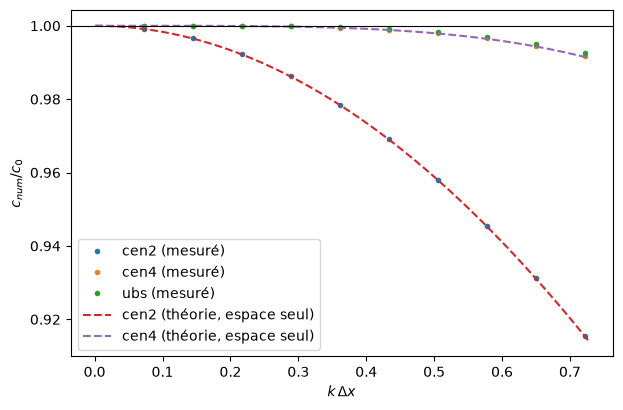

In [440]:
dx = 10000 #[m]
dt = 24*3600 #[s]
c0 = 0.5 #[m/s]
theta_max = min(np.pi, np.pi*dx/(c0*dt))
k_max = theta_max/dx

def phase_speed(f, dx, dt):
    """f[t, x] -> k, c(k) mesuré par la rotation de phase entre pas de temps."""
    F = np.fft.rfft(f - f.mean(axis=1, keepdims=True), axis=1)
    k = 2*np.pi*np.fft.rfftfreq(f.shape[1], dx)
    dphi = np.angle(F[1:] / F[:-1])          # = -ω dt avec la convention numpy
    w = np.abs(F[1:] * F[:-1])               # pondération par l'amplitude
    c = np.full(k.shape, np.nan)
    for i in range(1, len(k)):
        c[i] = -np.sum(w[:, i] * dphi[:, i]) / (np.sum(w[:, i]) * k[i] * dt)
    return k, c

theta = np.linspace(1e-3, theta_max, 400)                       # θ = k·dx
theory = {
    'cen2': np.sin(theta) / theta,
    'cen4': (4/3*np.sin(theta) - 1/6*np.sin(2*theta)) / theta,
}

fig, ax = plt.subplots(figsize=(7, 4.5))
for name, f in fields.items():
    k, c = phase_speed(f, dx, dt)
    k=k[ k*dx < theta_max]
    c = c[:len(k)]
    ax.plot(k*dx, c / c0, '.', label=f'{name} (mesuré)')
for name, c_th in theory.items():
    ax.plot(theta, c_th, '--', label=f'{name} (théorie, espace seul)')
ax.axhline(1, color='k', lw=0.8)
ax.set_xlabel(r'$k\,\Delta x$')
ax.set_ylabel(r'$c_{num}/c_0$')
ax.legend()
plt.show()

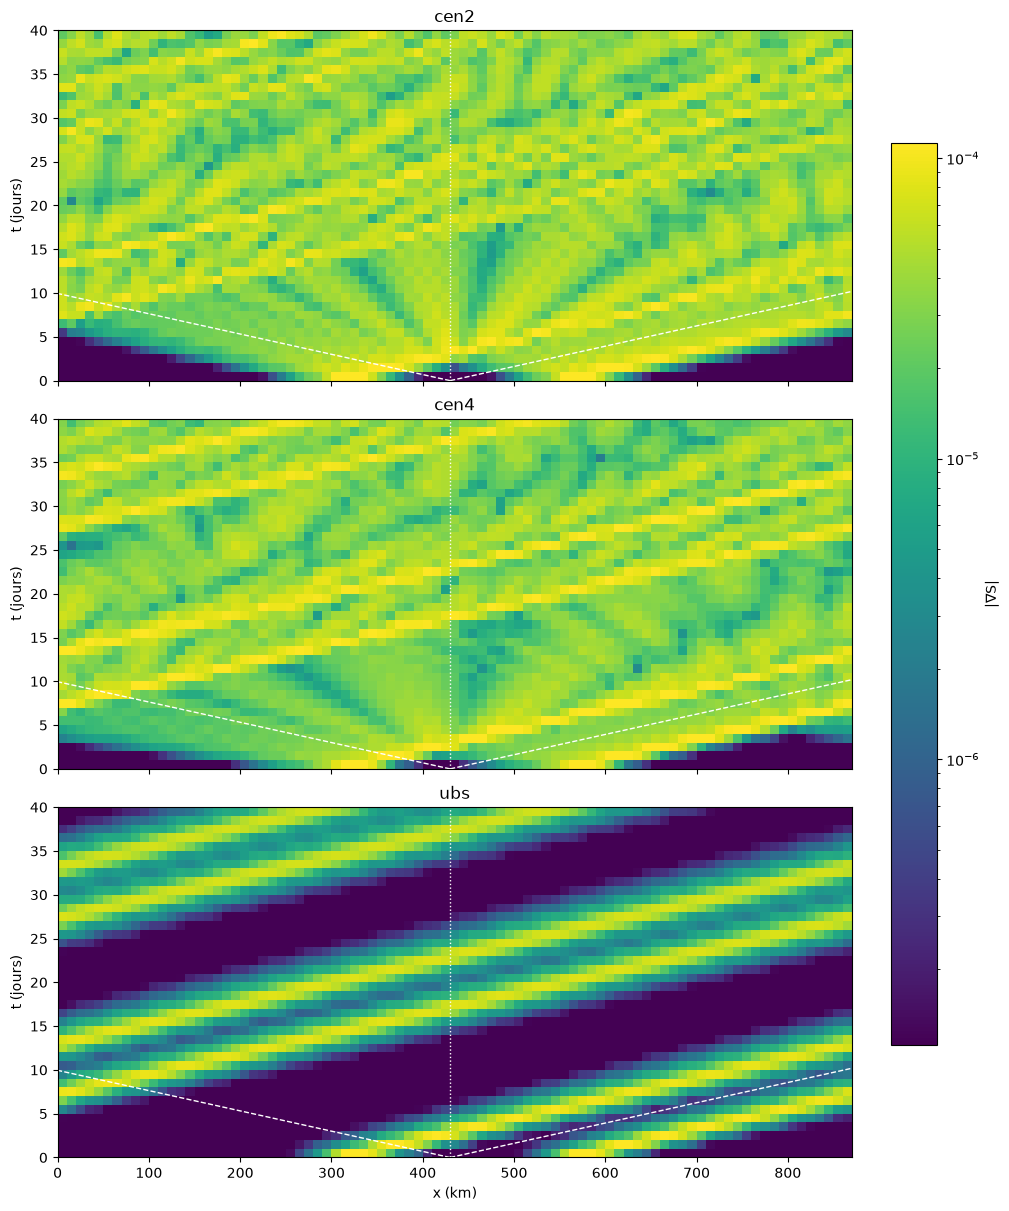

In [431]:
from matplotlib.colors import LogNorm

dx, dt, c0, xs = 10000., 24*3600., 0.5, 43     # xs : indice de la source, à ajuster
nt = 40
g = {n: ds['sssgrad'].isel(y_grid_T=50, time_counter=slice(0, nt)).values
     for n, ds in schemes.items()}
nx = next(iter(g.values())).shape[1]

vmax = np.nanpercentile(np.concatenate([a.ravel() for a in g.values()]), 99)
norm = LogNorm(vmin=vmax*1e-3, vmax=vmax)     # clip automatique des zéros

t = np.linspace(0, nt*dt, 100)
fig, axes = plt.subplots(len(g), 1, figsize=(10, 12),
                         sharex=True, sharey=True, constrained_layout=True)
for ax, (name, a) in zip(axes, g.items()):
    im = ax.imshow(np.clip(a, norm.vmin, None), origin='lower', aspect='auto',
                   cmap='viridis', norm=norm, interpolation='nearest',
                   extent=[0, nx*dx/1e3, 0, nt*dt/86400])
    # cône théorique en advection pure, et vitesse de groupe nulle
    for sgn in (+1, -1):
        ax.plot((xs*dx + sgn*c0*t)/1e3, t/86400, 'w--', lw=1)
    ax.axvline(xs*dx/1e3, color='w', ls=':', lw=1)
    ax.set_title(name); ax.set_ylabel('t (jours)')
    ax.set_xlim(0, nx*dx/1e3); ax.set_ylim(0, nt*dt/86400)
axes[-1].set_xlabel('x (km)')
fig.colorbar(im, ax=axes, label='|∇S|', shrink=0.8)
plt.show()

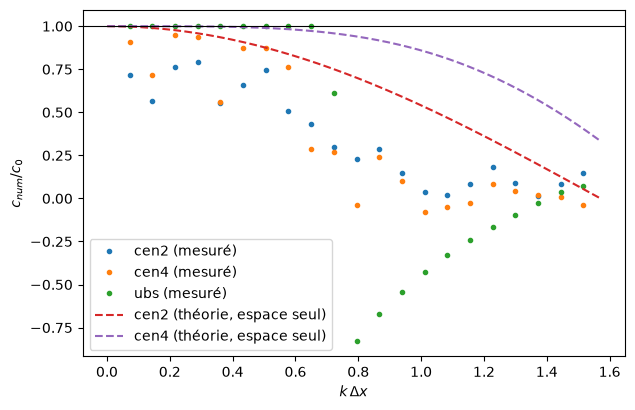

In [436]:
dx = 10000 #[m]
dt = 24*3600 #[s]
c0 = 0.5 #[m/s]
theta_max = min(np.pi/2, np.pi/2) #, np.pi*dx/(c0*dt))
k_max = theta_max/dx

def phase_speed(f, dx, dt):
    """f[t, x] -> k, c(k) mesuré par la rotation de phase entre pas de temps."""
    F = np.fft.rfft(f - f.mean(axis=1, keepdims=True), axis=1)
    k = 2*np.pi*np.fft.rfftfreq(f.shape[1], dx)
    dphi = np.angle(F[1:] / F[:-1])          # = -ω dt avec la convention numpy
    w = np.abs(F[1:] * F[:-1])               # pondération par l'amplitude
    c = np.full(k.shape, np.nan)
    for i in range(1, len(k)):
        c[i] = -np.sum(w[:, i] * dphi[:, i]) / (np.sum(w[:, i]) * k[i] * dt)
    return k, c

theta = np.linspace(1e-3, theta_max, 400)                       # θ = k·dx
theory = {
    'cen2': np.cos(theta),
    'cen4': (4/3*np.cos(theta) - 1/3*np.cos(2*theta)),
}

fig, ax = plt.subplots(figsize=(7, 4.5))
for name, f in g.items():
    k, c = phase_speed(f, dx, dt)
    k=k[ k*dx < theta_max]
    c = c[:len(k)]
    ax.plot(k*dx, c / c0, '.', label=f'{name} (mesuré)')
for name, c_th in theory.items():
    ax.plot(theta, c_th, '--', label=f'{name} (théorie, espace seul)')
ax.axhline(1, color='k', lw=0.8)
ax.set_xlabel(r'$k\,\Delta x$')
ax.set_ylabel(r'$c_{num}/c_0$')
ax.legend()
plt.show()

In [123]:
cen2.close()
ubs.close()
fct2.close()